# Question 2: Rwandan TVET Student Performance

## Scenario
Predicting Pass/Fail outcomes among fictional students
at a Rwandan TVET institution.

## Dataset
1,000 synthetic student records.

## Machine Learning Task
Binary classification: Pass or Fail.

## Important
All records are artificially generated for educational
purposes. They do not represent actual Rwandan students.

## Reproducibility
The dataset uses a fixed random seed (42).


In [2]:

import numpy as np
import pandas as pd
from pathlib import Path

rng = np.random.default_rng(42)
n = 1000

# Create fictional student attributes
df_tvet = pd.DataFrame({
    "student_id": [
        f"TVET{i:04d}" for i in range(1, n + 1)
    ],
    "district": rng.choice(
        ["Gasabo", "Kicukiro", "Nyarugenge",
         "Huye", "Musanze", "Rubavu"],
        n
    ),
    "tvet_level": rng.choice(
        ["Level 3", "Level 4", "Level 5"], n
    ),
    "department": rng.choice(
        ["ICT", "Electrical", "Construction",
         "Automotive", "Hospitality"], n
    ),
    "attendance_rate": np.round(
        rng.uniform(45, 100, n), 1
    ),
    "study_hours_per_week": rng.integers(
        2, 31, n
    ),
    "assignment_average": np.round(
        rng.uniform(30, 100, n), 1
    ),
    "previous_term_mark": np.round(
        rng.uniform(25, 100, n), 1
    ),
    "internet_access": rng.choice(
        ["Yes", "No"], n, p=[0.7, 0.3]
    ),
    "distance_to_school_km": np.round(
        rng.uniform(0.5, 25, n), 1
    ),
    "continuous_assessment_average": np.round(
        rng.uniform(30, 100, n), 1
    )
})

# Create an illustrative outcome mechanism
# This is NOT an official TVET grading formula.
score = (
    0.15 * df_tvet["attendance_rate"]
    + 0.10 * df_tvet["study_hours_per_week"]
    + 0.25 * df_tvet["assignment_average"]
    + 0.20 * df_tvet["previous_term_mark"]
    + 0.25 * df_tvet["continuous_assessment_average"]
    + rng.normal(0, 8, n)
)

df_tvet["pass_fail"] = np.where(
    score >= 50, "Pass", "Fail"
)

print("Dataset shape:", df_tvet.shape)
display(df_tvet.head())


Dataset shape: (1000, 12)


,student_id,district,tvet_level,department,attendance_rate,study_hours_per_week,assignment_average,previous_term_mark,internet_access,distance_to_school_km,continuous_assessment_average,pass_fail
0,TVET0001,Gasabo,Level 5,Hospitality,82.0,7,88.0,78.7,Yes,11.7,82.0,Pass
1,TVET0002,Musanze,Level 5,ICT,97.8,2,71.6,51.8,Yes,3.4,93.1,Pass
2,TVET0003,Huye,Level 4,Electrical,65.4,20,47.1,88.9,No,14.4,71.9,Pass
3,TVET0004,Nyarugenge,Level 5,Construction,68.4,21,82.2,43.1,Yes,4.3,67.0,Pass
4,TVET0005,Nyarugenge,Level 3,Automotive,89.7,24,35.9,65.4,Yes,2.0,92.3,Pass


In [3]:

print("Rows and columns:", df_tvet.shape)
print("Duplicate IDs:",
      df_tvet["student_id"].duplicated().sum())
print("Missing values:",
      df_tvet.isnull().sum().sum())

print("\nPass/Fail distribution:")
print(df_tvet["pass_fail"].value_counts())

print("\nData types:")
print(df_tvet.dtypes)


Rows and columns: (1000, 12)
Duplicate IDs: 0
Missing values: 0

Pass/Fail distribution:
pass_fail
Pass    724
Fail    276
Name: count, dtype: int64

Data types:
student_id                        object
district                          object
tvet_level                        object
department                        object
attendance_rate                  float64
study_hours_per_week               int64
assignment_average               float64
previous_term_mark               float64
internet_access                   object
distance_to_school_km            float64
continuous_assessment_average    float64
pass_fail                         object
dtype: object


In [4]:

raw_path = Path(
    "../data/raw/tvet_student_performance_synthetic_raw.csv"
)

raw_path.parent.mkdir(parents=True, exist_ok=True)

df_tvet.to_csv(raw_path, index=False)

print("Saved:", raw_path)


Saved: ../data/raw/tvet_student_performance_synthetic_raw.csv


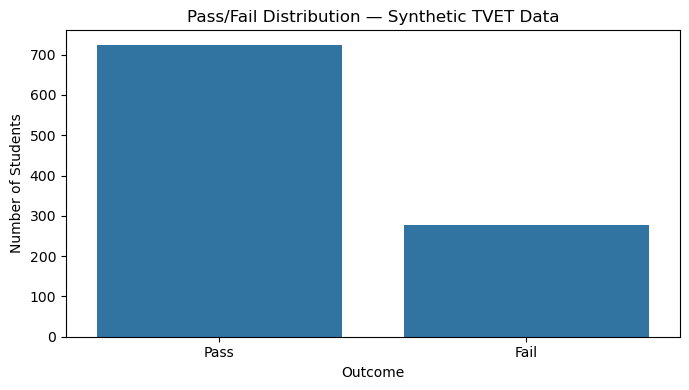

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df_tvet,
    x="pass_fail",
    order=["Pass", "Fail"]
)

plt.title("Pass/Fail Distribution — Synthetic TVET Data")
plt.xlabel("Outcome")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


In [6]:

# Inspect the synthetic TVET dataset

print("Dataset shape:", df_tvet.shape)

print("\nMissing values:")
print(df_tvet.isnull().sum())

print("\nDuplicate rows:")
print(df_tvet.duplicated().sum())

print("\nDuplicate student IDs:")
print(df_tvet["student_id"].duplicated().sum())

print("\nPass/Fail distribution:")
print(df_tvet["pass_fail"].value_counts())

print("\nSummary statistics:")
display(df_tvet.describe())

display(df_tvet.head())


Dataset shape: (1000, 12)

Missing values:
student_id                       0
district                         0
tvet_level                       0
department                       0
attendance_rate                  0
study_hours_per_week             0
assignment_average               0
previous_term_mark               0
internet_access                  0
distance_to_school_km            0
continuous_assessment_average    0
pass_fail                        0
dtype: int64

Duplicate rows:
0

Duplicate student IDs:
0

Pass/Fail distribution:
pass_fail
Pass    724
Fail    276
Name: count, dtype: int64

Summary statistics:


,attendance_rate,study_hours_per_week,assignment_average,previous_term_mark,distance_to_school_km,continuous_assessment_average
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.0000,1000.000000
mean,72.440500,15.993000,64.550000,61.444000,12.6497,65.151700
std,15.885679,8.213672,20.319894,21.139648,6.9762,20.458825
min,45.000000,2.000000,30.000000,25.100000,0.5000,30.100000
25%,58.775000,9.000000,47.375000,43.175000,6.6750,47.800000
50%,72.050000,16.000000,64.600000,60.900000,12.6500,65.500000
75%,86.600000,23.000000,82.200000,79.425000,18.4000,82.550000
max,100.000000,30.000000,100.000000,100.000000,25.0000,100.000000


,student_id,district,tvet_level,department,attendance_rate,study_hours_per_week,assignment_average,previous_term_mark,internet_access,distance_to_school_km,continuous_assessment_average,pass_fail
0,TVET0001,Gasabo,Level 5,Hospitality,82.0,7,88.0,78.7,Yes,11.7,82.0,Pass
1,TVET0002,Musanze,Level 5,ICT,97.8,2,71.6,51.8,Yes,3.4,93.1,Pass
2,TVET0003,Huye,Level 4,Electrical,65.4,20,47.1,88.9,No,14.4,71.9,Pass
3,TVET0004,Nyarugenge,Level 5,Construction,68.4,21,82.2,43.1,Yes,4.3,67.0,Pass
4,TVET0005,Nyarugenge,Level 3,Automotive,89.7,24,35.9,65.4,Yes,2.0,92.3,Pass


In [7]:

# Check numerical ranges

range_checks = {
    "attendance_rate": (0, 100),
    "study_hours_per_week": (0, 168),
    "assignment_average": (0, 100),
    "previous_term_mark": (0, 100),
    "distance_to_school_km": (0, 100),
    "continuous_assessment_average": (0, 100)
}

for col, (minimum, maximum) in range_checks.items():
    invalid = (
        (df_tvet[col] < minimum) |
        (df_tvet[col] > maximum)
    ).sum()

    print(f"{col}: {invalid} invalid values")

print("\nUnexpected target values:")
print(
    set(df_tvet["pass_fail"].dropna().unique())
    - {"Pass", "Fail"}
)


attendance_rate: 0 invalid values
study_hours_per_week: 0 invalid values
assignment_average: 0 invalid values
previous_term_mark: 0 invalid values
distance_to_school_km: 0 invalid values
continuous_assessment_average: 0 invalid values

Unexpected target values:
set()


In [8]:

# Preserve the raw dataset
df_clean_tvet = df_tvet.copy()

# Remove exact duplicates
df_clean_tvet = df_clean_tvet.drop_duplicates()

# Ensure numeric columns have numeric types
numeric_cols = [
    "attendance_rate",
    "study_hours_per_week",
    "assignment_average",
    "previous_term_mark",
    "distance_to_school_km",
    "continuous_assessment_average"
]

for col in numeric_cols:
    df_clean_tvet[col] = pd.to_numeric(
        df_clean_tvet[col],
        errors="coerce"
    )

print("Cleaned shape:", df_clean_tvet.shape)
print("Missing values:", df_clean_tvet.isna().sum().sum())


Cleaned shape: (1000, 12)
Missing values: 0


In [10]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

clean_path = output_dir / "tvet_student_performance_clean.csv"

df_clean_tvet.to_csv(clean_path, index=False)

print("Cleaned dataset saved:", clean_path)


Cleaned dataset saved: ../data/processed/tvet_student_performance_clean.csv


In [11]:

X = df_clean_tvet.drop(
    columns=["student_id", "pass_fail"]
)

y = df_clean_tvet["pass_fail"]

print("Input features:", X.shape[1])
print("Target classes:", y.unique())

print("\nFeature names:")
print(X.columns.tolist())


Input features: 10
Target classes: ['Pass' 'Fail']

Feature names:
['district', 'tvet_level', 'department', 'attendance_rate', 'study_hours_per_week', 'assignment_average', 'previous_term_mark', 'internet_access', 'distance_to_school_km', 'continuous_assessment_average']


In [12]:

from sklearn.model_selection import train_test_split

print("Class distribution:")
print(y.value_counts())

assert y.nunique() == 2, (
    "Both Pass and Fail must be present."
)

assert y.value_counts().min() >= 2, (
    "Each class needs at least two records."
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Class distribution:
pass_fail
Pass    724
Fail    276
Name: count, dtype: int64
Training records: 800
Testing records: 200


In [13]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

categorical_features = [
    "district",
    "tvet_level",
    "department",
    "internet_access"
]

numerical_features = [
    "attendance_rate",
    "study_hours_per_week",
    "assignment_average",
    "previous_term_mark",
    "distance_to_school_km",
    "continuous_assessment_average"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_tvet = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit using training data only
X_train_ready = preprocessor_tvet.fit_transform(X_train)

# Transform testing data without refitting
X_test_ready = preprocessor_tvet.transform(X_test)

print("Training shape:", X_train_ready.shape)
print("Testing shape:", X_test_ready.shape)


Training shape: (800, 22)
Testing shape: (200, 22)


In [14]:

feature_names = preprocessor_tvet.get_feature_names_out()

train_ready_df = pd.DataFrame(
    X_train_ready,
    columns=feature_names,
    index=X_train.index
)

test_ready_df = pd.DataFrame(
    X_test_ready,
    columns=feature_names,
    index=X_test.index
)

# Add the target back
train_ready_df["pass_fail"] = y_train
test_ready_df["pass_fail"] = y_test

print("ML-ready training data:")
display(train_ready_df.head())

print("Missing values in training:",
      train_ready_df.isnull().sum().sum())

print("Missing values in testing:",
      test_ready_df.isnull().sum().sum())


ML-ready training data:


,numeric__attendance_rate,numeric__study_hours_per_week,numeric__assignment_average,numeric__previous_term_mark,numeric__distance_to_school_km,numeric__continuous_assessment_average,categorical__district_Gasabo,categorical__district_Huye,categorical__district_Kicukiro,categorical__district_Musanze,...,categorical__tvet_level_Level 4,categorical__tvet_level_Level 5,categorical__department_Automotive,categorical__department_Construction,categorical__department_Electrical,categorical__department_Hospitality,categorical__department_ICT,categorical__internet_access_No,categorical__internet_access_Yes,pass_fail
905,-0.892279,-1.217783,0.613278,0.298972,1.154435,-1.074396,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,Fail
942,-1.050002,-1.095130,-1.031487,0.379456,0.207015,0.640485,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,Pass
991,-0.356020,-0.113913,-0.233726,1.302648,-0.812179,1.515025,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,Pass
653,1.025633,-0.113913,-0.992091,-1.291759,0.135241,-1.577623,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,Fail
1,1.580818,-1.708391,0.357207,-0.463253,-1.300244,1.368454,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,Pass


Missing values in training: 0
Missing values in testing: 0


In [15]:

import joblib

train_ready_df.to_csv(
    output_dir / "tvet_train_ml_ready.csv",
    index=False
)

test_ready_df.to_csv(
    output_dir / "tvet_test_ml_ready.csv",
    index=False
)

joblib.dump(
    preprocessor_tvet,
    output_dir / "tvet_preprocessor.joblib"
)

print("All TVET ML-ready files saved successfully!")


All TVET ML-ready files saved successfully!


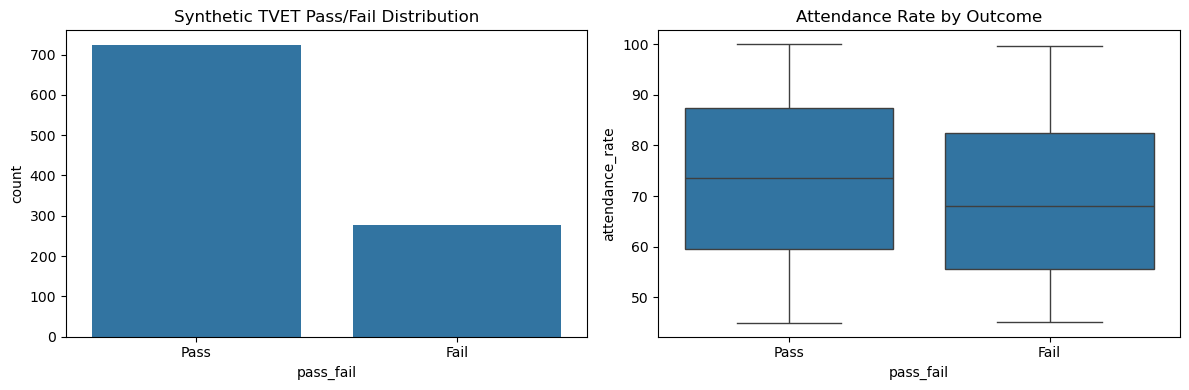

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df_clean_tvet,
    x="pass_fail",
    order=["Pass", "Fail"],
    ax=axes[0]
)
axes[0].set_title("Synthetic TVET Pass/Fail Distribution")

sns.boxplot(
    data=df_clean_tvet,
    x="pass_fail",
    y="attendance_rate",
    order=["Pass", "Fail"],
    ax=axes[1]
)
axes[1].set_title("Attendance Rate by Outcome")

plt.tight_layout()
plt.show()


In [17]:

assert len(df_clean_tvet) == 1000
assert X.shape[1] == 10
assert len(train_ready_df) == 800
assert len(test_ready_df) == 200

assert train_ready_df.isnull().sum().sum() == 0
assert test_ready_df.isnull().sum().sum() == 0

assert list(train_ready_df.columns) == list(test_ready_df.columns)

print("SUCCESS: Question 2 preprocessing checks passed!")


SUCCESS: Question 2 preprocessing checks passed!
